In [1]:
import numpy as np
import joblib
import pandas as pd

# Load trained artifacts
xgb_model = joblib.load("../models/xgb_price_model.pkl")
le_district = joblib.load("../models/district_encoder.pkl")
le_commodity = joblib.load("../models/commodity_encoder.pkl")

df = pd.read_csv("../data/processed/phase2_feature_complete.csv")
df = df.sort_values("date")

sample = df.iloc[-1]

district_enc = le_district.transform([sample["district"]])[0]
commodity_enc = le_commodity.transform([sample["commodity"]])[0]

features = np.array([[ 
    sample["min_price"],
    sample["max_price"],
    sample["temp_max"],
    sample["temp_min"],
    sample["rainfall"],
    sample["wind_speed"],
    sample["modal_price_lag_1"],
    sample["modal_price_lag_7"],
    sample["modal_price_lag_14"],
    district_enc,
    commodity_enc
]])

print("Feature Shape:", features.shape)
assert features.shape[1] == 11
print("✅ Feature shape validation passed")

Feature Shape: (1, 11)
✅ Feature shape validation passed


In [2]:
subset = df[
    (df["district"] == sample["district"]) &
    (df["commodity"] == sample["commodity"])
].sort_values("date")

check_index = 20

print("Lag 1 Check:",
      subset.iloc[check_index]["modal_price_lag_1"] ==
      subset.iloc[check_index-1]["modal_price"])

print("Lag 7 Check:",
      subset.iloc[check_index]["modal_price_lag_7"] ==
      subset.iloc[check_index-7]["modal_price"])

print("Lag 14 Check:",
      subset.iloc[check_index]["modal_price_lag_14"] ==
      subset.iloc[check_index-14]["modal_price"])

Lag 1 Check: True
Lag 7 Check: True
Lag 14 Check: True


In [3]:
print("District Classes:", le_district.classes_[:5])
print("Commodity Classes:", le_commodity.classes_[:5])

print("Encoded Ahmednagar:",
      le_district.transform(["Ahmednagar"]))

District Classes: ['Ahmednagar' 'Akola' 'Amarawati' 'Beed' 'Bhandara']
Commodity Classes: ['Ajwan' 'Almond (Badam)' 'Amla (Nelli Kai)' 'Apple'
 'Arecanut (Betelnut/Supari)']
Encoded Ahmednagar: [0]


In [6]:
try:
    le_district.transform(["InvalidDistrict"])
except Exception as e:
    print("✅ Invalid input caught:", str(e))

✅ Invalid input caught: y contains previously unseen labels: 'InvalidDistrict'


In [7]:
def compute_risk(sentiment, news_count):
    if news_count == 0:
        return 0
    return abs(sentiment) * news_count

print("Test Case 1:", compute_risk(0.5, 10))  # Expect 5
print("Test Case 2:", compute_risk(-0.3, 5))  # Expect 1.5
print("Test Case 3:", compute_risk(0, 10))    # Expect 0

Test Case 1: 5.0
Test Case 2: 1.5
Test Case 3: 0


In [8]:
import numpy as np

def safety_stock(demand_std, lead_time_days, risk, horizon):
    z = 1.65
    base = z * demand_std * np.sqrt(lead_time_days)
    horizon_multiplier = 1 + (horizon / 60)
    risk_multiplier = 1 + min(risk / 20, 0.5)
    return base * horizon_multiplier * risk_multiplier

low = safety_stock(100, 5, risk=0, horizon=1)
high = safety_stock(100, 5, risk=5, horizon=60)

print("Low Risk Stock:", low)
print("High Risk Stock:", high)
print("Stock increases under risk:", high > low)

Low Risk Stock: 375.10040322558973
High Risk Stock: 922.3780407186633
Stock increases under risk: True


In [9]:
BASE_CONFIDENCE = 90
DECAY = 0.4

for days in [1, 10, 30, 60]:
    confidence = max(30, BASE_CONFIDENCE - days * DECAY)
    print(f"Horizon {days} days → Confidence {confidence}%")

Horizon 1 days → Confidence 89.6%
Horizon 10 days → Confidence 86.0%
Horizon 30 days → Confidence 78.0%
Horizon 60 days → Confidence 66.0%


In [11]:
from datetime import timedelta

last_date = pd.to_datetime(df["date"].max())
test_date = last_date + timedelta(days=1)

print("Last Date:", last_date)
print("Next Forecast Date:", test_date)
print("Days Ahead:", (test_date - last_date).days)

Last Date: 2024-12-31 00:00:00
Next Forecast Date: 2025-01-01 00:00:00
Days Ahead: 1


In [12]:
from datetime import timedelta

last_date = pd.to_datetime(df["date"].max())
test_date = last_date + timedelta(days=1)

print("Last Date:", last_date)
print("Next Forecast Date:", test_date)
print("Days Ahead:", (test_date - last_date).days)

Last Date: 2024-12-31 00:00:00
Next Forecast Date: 2025-01-01 00:00:00
Days Ahead: 1


In [14]:
import pandas as pd
import numpy as np
import joblib
from tensorflow.keras.models import load_model
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

# Load dataset
df_model = pd.read_csv("../data/processed/phase2_feature_complete.csv")
df_model = df_model.sort_values(['district','commodity','date']).reset_index(drop=True)

# Load models
xgb_model = joblib.load("../models/xgb_price_model.pkl")
model_lstm = load_model("../models/lstm_residual_v1.keras")
scaler_lstm = joblib.load("../models/lstm_residual_scaler_v1.pkl")

print("Models loaded successfully.")

Models loaded successfully.


In [20]:
# Load encoders
le_district = joblib.load("../models/district_encoder.pkl")
le_commodity = joblib.load("../models/commodity_encoder.pkl")

df_model['district_enc'] = le_district.transform(df_model['district'])
df_model['commodity_enc'] = le_commodity.transform(df_model['commodity'])

# Ensure correct feature order
X_all = df_model[[
    'min_price',
    'max_price',
    'temp_max',
    'temp_min',
    'rainfall',
    'wind_speed',
    'modal_price_lag_1',
    'modal_price_lag_7',
    'modal_price_lag_14',
    'district_enc',
    'commodity_enc'
]]

df_model['xgb_pred'] = xgb_model.predict(X_all)
df_model['residual'] = df_model['modal_price'] - df_model['xgb_pred']

In [21]:
df_model['residual'].describe()

count    1.641710e+05
mean     3.092745e+02
std      1.258178e+05
min     -6.836959e+04
25%     -9.070923e+01
50%     -5.561401e+00
75%      8.189465e+01
max      5.097825e+07
Name: residual, dtype: float64

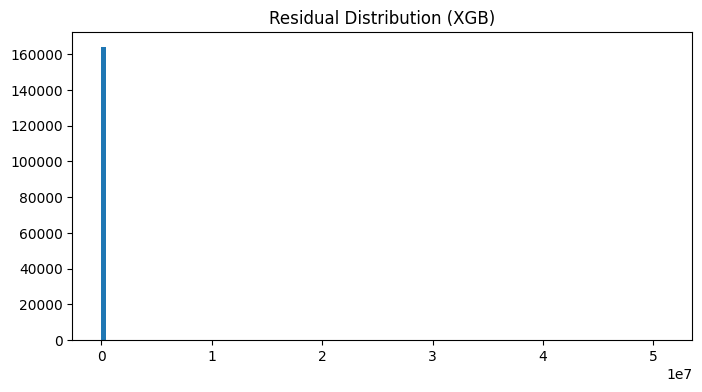

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,4))
plt.hist(df_model['residual'], bins=100)
plt.title("Residual Distribution (XGB)")
plt.show()

In [23]:
def build_lstm_sequences(df, seq_len=30):
    X = []

    for _, group in df.groupby(['district','commodity']):
        values = group[['modal_price','residual']].values

        if len(values) <= seq_len:
            continue

        for i in range(seq_len, len(values)):
            X.append(values[i-seq_len:i])

    return np.array(X)

X_lstm = build_lstm_sequences(df_model, seq_len=30)

print("LSTM shape:", X_lstm.shape)

LSTM shape: (135901, 30, 2)


In [24]:
from tensorflow.keras.models import load_model

model_lstm = load_model("../models/lstm_residual_v1.keras")
scaler_lstm = joblib.load("../models/lstm_residual_scaler_v1.pkl")

In [26]:
X_scaled = scaler_lstm.fit_transform(X_reshaped)
y_lstm_scaled = scaler_lstm.fit_transform(y_lstm.reshape(-1, 1))

NameError: name 'y_lstm' is not defined